# DAR ES SALAAM INSTITUTE OF TECHNOLOGY

## DIGITAL SIGNAL PROCESSING LABORATORY

**Module Code:** COU 07506

**Laboratory:** Week 1 – Lab 0: Setting Up the DSP Laboratory

**Name:** Victoria Bintu Birhanenwa

**Registration Number:** Your Registration Number

**Class:** Your Class

**Date:** 22 November 2026

**Academic Year:** 2026/2027

---

### WEEK 1: SETTING UP THE DSP LABORATORY

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)


TASK 1.1 — GENERATING ELEMENTARY DISCRETE-TIME SIGNALS

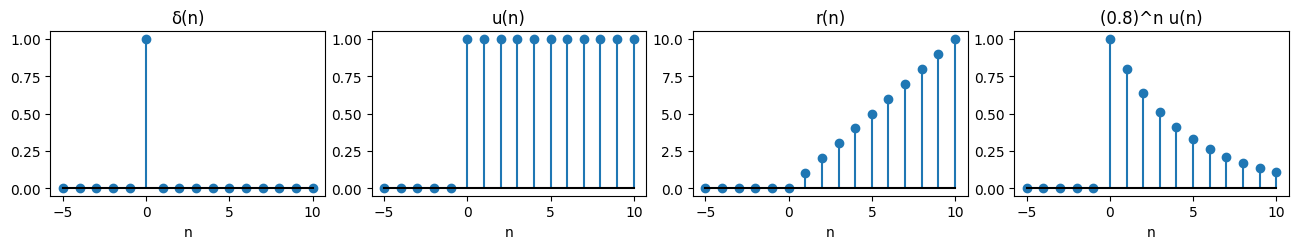

In [2]:

# Generate discrete-time indices
n = np.arange(-5, 11)

# Generate four elementary signals
delta = (n == 0).astype(float)  # Unit impulse
step = (n >= 0).astype(float)   # Unit step
ramp = n * step                # Unit ramp
expo = 0.8**n * step           # Real exponential

# Create four plots
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))

for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]
):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")

plt.tight_layout()
plt.show()


TASK 1.2 — CHANGING SIGNAL PARAMETERS

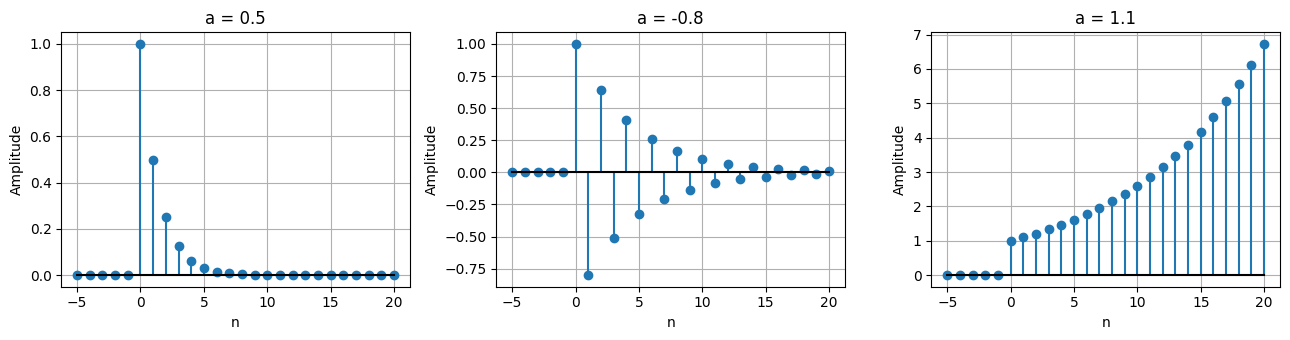

In [3]:

# Define the time index
n = np.arange(-5, 21)

# Define the three values of a
values = [0.5, -0.8, 1.1]

# Create subplots
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

# Generate and plot each exponential signal
for ax, a in zip(axes, values):
    x = (a**n) * (n >= 0)
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()


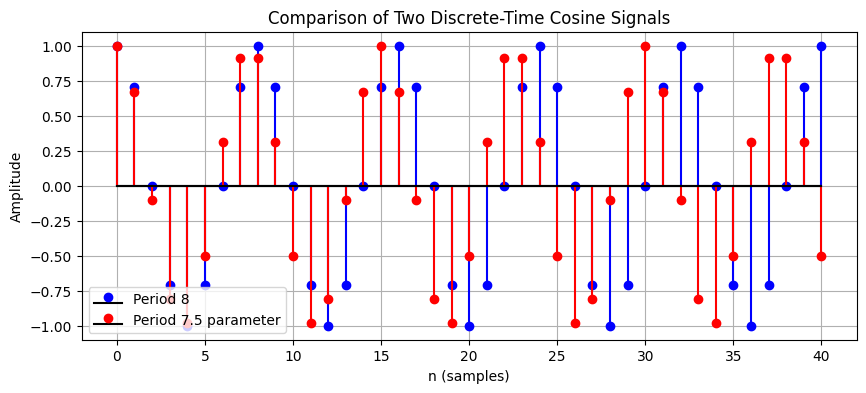

In [4]:

# Generate time indices
n = np.arange(0, 41)

# Generate cosine signals
x1 = np.cos(2*np.pi*n/8)
x2 = np.cos(2*np.pi*n/7.5)

# Plot both signals
plt.figure(figsize=(10, 4))

plt.stem(n, x1, linefmt="b-", markerfmt="bo",
         basefmt="k-", label="Period 8")

plt.stem(n, x2, linefmt="r-", markerfmt="ro",
         basefmt="k-", label="Period 7.5 parameter")

plt.xlabel("n (samples)")
plt.ylabel("Amplitude")
plt.title("Comparison of Two Discrete-Time Cosine Signals")
plt.legend()
plt.grid(True)
plt.show()


1.2 — Observations

**Part A: Exponential signals**

- When \(a = 0.5\), the signal is positive and decreases towards zero.
- When \(a = -0.8\), the signal alternates between positive and negative values, while its magnitude decreases towards zero.
- When \(a = 1.1\), the signal increases as \(n\) increases.

**Part B: Discrete-time cosine signals**

- The signal \(x_1(n) = \cos(2\pi n/8)\) repeats after 8 samples.
- The signal \(x_2(n) = \cos(2\pi n/7.5)\) repeats after 15 samples.

**Conclusion:** Both discrete-time cosine signals are periodic. Their fundamental periods are 8 and 15 samples, respectively.

In [6]:
!file "Voice signal.wav"

Voice signal.wav: ISO Media, Apple iTunes ALAC/AAC-LC (.M4A) Audio


In [7]:
!ffmpeg -i "Voice signal.wav" -ac 1 -ar 16000 my_voice.wav

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [8]:
fname = "my_voice.wav"

fs, x = wavfile.read(fname)

if x.ndim > 1:
    x = x.mean(axis=1)

x = x.astype(float)
x = x / np.max(np.abs(x))

print("Recording loaded successfully!")
print("Sampling frequency:", fs, "Hz")
print("Number of samples:", len(x))
print("Duration:", round(len(x) / fs, 2), "seconds")

Recording loaded successfully!
Sampling frequency: 16000 Hz
Number of samples: 83627
Duration: 5.23 seconds


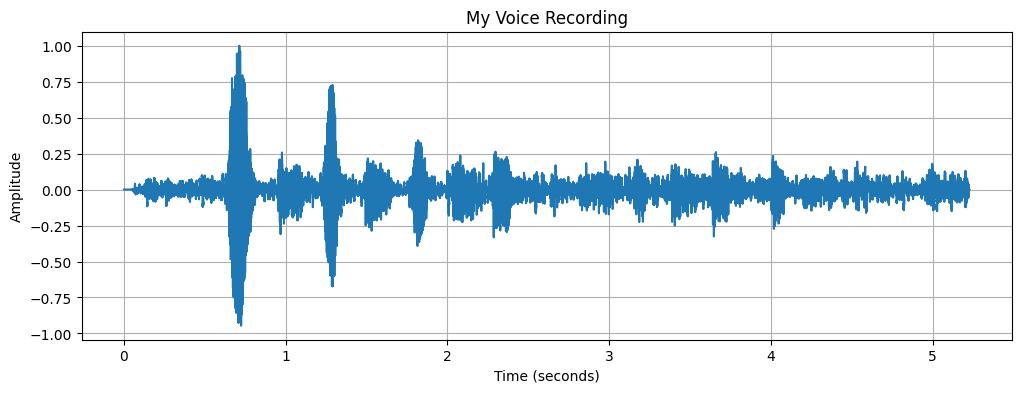

In [9]:
t = np.arange(len(x)) / fs

plt.figure(figsize=(12, 4))
plt.plot(t, x)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("My Voice Recording")
plt.grid(True)
plt.show()

In [10]:
from IPython.display import Audio, display

display(Audio(x, rate=fs))

### Task 1.3 — Observations

1. The recorded voice signal was successfully loaded into Python.
2. The recording has a sampling frequency of 16,000 Hz.
3. The audio duration is approximately 5.23 seconds.
4. The waveform shows how the signal amplitude changes over time.
5. The audio was successfully played back using Python.

**Conclusion:** The experiment demonstrated how to record, load, visualize and play a digital audio signal using Python.



### Question 1
**What is the sampling rate of your phone's recording? How many numbers are needed to store one minute of it in mono?**

The sampling rate of my recording is **16,000 Hz**, meaning that 16,000 audio samples are recorded every second.

For one minute:

Number of samples = Sampling rate × Duration

= 16,000 × 60

= **960,000 samples**

Therefore, 960,000 numbers are needed to store one minute of mono audio at a sampling rate of 16,000 Hz.

### Question 2
**Why is a stem plot more appropriate than a continuous line for x(n)?**

A stem plot is more appropriate because a discrete-time signal is defined only at separate integer sample positions. It displays individual samples clearly using vertical lines and markers. A continuous line may incorrectly suggest that the signal has values between those sample positions.

### Question 3
**For a = 1.1 the exponential grows. Which property of a system would such a signal violate if it were an impulse response?**

It would violate the **BIBO stability property (Bounded-Input, Bounded-Output stability)**.

This is because an impulse response that grows exponentially does not have a finite sum of absolute values. Consequently, the system would not be BIBO stable.